# 02 — Baseline_MobileNetV2_CrossDomain

Notebook ini mengevaluasi full 1,280-dimensional deep features menggunakan
Linear Support Vector Machine (Linear SVM).

Feature representations:
1. MobileNetV2


Training regimes:
- Dataset A
- Dataset B
- Combined Dataset A+B

Evaluation:
- A → A
- B → B
- A+B → Combined Test
- A+B → Test A
- A+B → Test B
- A → B
- B → A

Hyperparameter C dipilih hanya dari training data menggunakan repeated
StratifiedGroupKFold. Test data tidak digunakan untuk model selection.

In [ ]:
# ============================================================
# CELL 1 — MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive

drive.mount(
    "/content/drive"
)

Mounted at /content/drive


In [ ]:
# ============================================================
# CELL 2 — IMPORT LIBRARY
# ============================================================

from pathlib import Path
from datetime import datetime
from itertools import product

import hashlib
import json
import joblib
import time

import numpy as np
import pandas as pd

from IPython.display import display

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support
)

from sklearn.model_selection import (
    StratifiedGroupKFold
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.utils import resample

print("Library siap.")

Library siap.


In [ ]:
# ============================================================
# CELL 3 — PATH PROYEK FINAL
# MobileNetV2 Frozen + Linear SVM
# ============================================================

from pathlib import Path


ROOT_DIR = Path(
    "/content/drive/MyDrive/eksperimen_baru"
)


BASELINE_DIR = (
    ROOT_DIR / "baseline_v2"
)


# ============================
# CONFIG DAN DATA AUDIT
# ============================

CONFIG_PATH = (
    BASELINE_DIR / "config/config.json"
)


AUDIT_PATH = (
    BASELINE_DIR / "logs/data_audit_status.json"
)


# ============================
# DATA SPLIT
# ============================

SPLIT_DIR = (
    BASELINE_DIR / "splits"
)


SPLIT_SIGNATURE_PATH = (
    SPLIT_DIR / "split_signatures.json"
)


# ============================
# FEATURE SOURCE
# MobileNetV2 pretrained ImageNet
# frozen feature extractor
# ============================

FEATURE_ROOT = (
    BASELINE_DIR
    / "features/frozen/mobilenetv2_frozen"
)


# ============================
# OUTPUT EKSPERIMEN FINAL
# ============================

RUN_DIR = (
    BASELINE_DIR
    / "multi_regime/svm_mobilenetv2_frozen"
)


MODEL_DIR = (
    RUN_DIR / "models"
)


CV_DIR = (
    RUN_DIR / "cv"
)


METRICS_DIR = (
    RUN_DIR / "metrics"
)


PREDICTION_DIR = (
    RUN_DIR / "predictions"
)


LOG_DIR = (
    RUN_DIR / "logs"
)


CONFUSION_DIR = (
    RUN_DIR / "confusion_matrix"
)


for directory in [
    MODEL_DIR,
    CV_DIR,
    METRICS_DIR,
    PREDICTION_DIR,
    LOG_DIR,
    CONFUSION_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )


print("Feature source:")
print(FEATURE_ROOT)


print("\nOutput directory:")
print(RUN_DIR)

Feature source:
/content/drive/MyDrive/eksperimen_baru/baseline_v2/features/frozen/mobilenetv2_frozen

Output directory:
/content/drive/MyDrive/eksperimen_baru/baseline_v2/multi_regime/svm_mobilenetv2_frozen


In [ ]:
import os
print(os.listdir(FROZEN_ROOT))

['train_a_labels.npy', 'train_a_index.csv', 'train_a_features.npy', 'val_a_index.csv', 'val_a_labels.npy', 'val_a_features.npy', 'test_a_labels.npy', 'test_a_index.csv', 'test_a_features.npy', 'train_b_features.npy', 'train_b_labels.npy', 'train_b_index.csv', 'val_b_features.npy', 'val_b_labels.npy', 'val_b_index.csv', 'test_b_index.csv', 'test_b_features.npy', 'test_b_labels.npy', 'train_ab_features.npy', 'external_a_full_features.npy', 'extraction_log.csv', 'metadata.json', 'external_b_full_labels.npy', 'external_b_full_index.csv', 'external_b_full_features.npy', 'train_ab_labels.npy', 'val_ab_labels.npy', 'val_ab_index.csv', 'train_ab_index.csv', 'val_ab_features.npy', 'test_ab_features.npy', 'test_ab_index.csv', 'test_ab_labels.npy', 'external_a_full_labels.npy', 'external_a_full_index.csv']


In [ ]:
# ============================================================
# CHECK FEATURE SOURCE
# MobileNetV2 Frozen Only
# ============================================================

print("Model:")
print("mobilenetv2_frozen")

print("\nFeature path:")
print(FEATURE_ROOT)


if FEATURE_ROOT.exists():
    print("\n✓ Feature tersedia")
else:
    print("\n✗ Feature tidak ditemukan")

Model:
mobilenetv2_frozen

Feature path:
/content/drive/MyDrive/eksperimen_baru/baseline_v2/features/frozen/mobilenetv2_frozen

✓ Feature tersedia


In [ ]:
# ============================================================
# CELL 4 — CONFIG DAN AUDIT GATE
# ============================================================

with open(CONFIG_PATH) as file:
    CONFIG = json.load(file)

with open(AUDIT_PATH) as file:
    AUDIT = json.load(file)

with open(SPLIT_SIGNATURE_PATH) as file:
    SPLIT_SIGNATURES = json.load(file)


if AUDIT["audit_status"] != "PASSED":
    raise RuntimeError(
        "Audit data belum PASSED."
    )

if AUDIT["blocking_issue_count"] != 0:
    raise RuntimeError(
        "Masih terdapat blocking issue."
    )


RANDOM_STATE = CONFIG["random_state"]

TARGET_CLASSES = (
    CONFIG["target_classes"]
)

N_CLASSES = len(
    TARGET_CLASSES
)

C_VALUES = (
    CONFIG["svm"]["c_values"]
)

CV_FOLDS = (
    CONFIG["svm"]["cv_n_splits"]
)

CV_SEEDS = (
    CONFIG["experiment_seeds"]
)

CLASS_WEIGHT = (
    CONFIG["svm"]["class_weight"]
)

MAX_ITER = (
    CONFIG["svm"]["max_iter"]
)

TOL = (
    CONFIG["svm"]["tolerance"]
)


print("Audit        : PASSED")
print("CV folds     :", CV_FOLDS)
print("CV seeds     :", CV_SEEDS)
print("C candidates :", C_VALUES)

Audit        : PASSED
CV folds     : 5
CV seeds     : [42, 52, 62, 72, 82]
C candidates : [1e-05, 0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0]


In [ ]:
# ============================================================
# CELL 5 — MEMBACA MASTER SPLIT
# ============================================================

SPLIT_NAMES = [
    "train_a", "val_a", "test_a",
    "train_b", "val_b", "test_b",
    "train_ab", "val_ab", "test_ab",
    "external_a_full",
    "external_b_full"
]


LABEL_TO_ID = {
    label: i
    for i, label
    in enumerate(TARGET_CLASSES)
}


splits = {}


for name in SPLIT_NAMES:

    path = (
        SPLIT_DIR
        / f"{name}.csv"
    )

    df = pd.read_csv(path)

    df["label_id"] = (
        df["label"]
        .map(LABEL_TO_ID)
        .astype(int)
    )

    splits[name] = (
        df.reset_index(drop=True)
    )


for name in SPLIT_NAMES:
    print(
        f"{name:<16}: "
        f"{len(splits[name])}"
    )

train_a         : 2620
val_a           : 327
test_a          : 329
train_b         : 192
val_b           : 24
test_b          : 24
train_ab        : 2812
val_ab          : 351
test_ab         : 353
external_a_full : 3276
external_b_full : 240


In [ ]:
# ============================================================
# CELL 6 — PROTOKOL EKSPERIMEN
# MobileNetV2 Frozen + Linear SVM
# ============================================================


REGIMES = {

    "a": {
        "train": "train_a",
        "val": "val_a"
    },

    "b": {
        "train": "train_b",
        "val": "val_b"
    },

    "ab": {
        "train": "train_ab",
        "val": "val_ab"
    }

}


# ============================
# MODEL UTAMA PENELITIAN
# ============================

MODEL_NAME = "mobilenetv2_frozen"


MODEL_LABEL = (
    "MobileNetV2 Frozen"
)



# ============================
# SKENARIO EKSPERIMEN
# ============================

EXPERIMENTS = [

    ("S1", "a", "A_to_A", "test_a"),

    ("S2", "b", "B_to_B", "test_b"),

    ("S3", "a", "A_to_B", "external_b_full"),

    ("S4", "b", "B_to_A", "external_a_full"),

    ("S5", "ab", "AB_to_AB", "test_ab"),

    ("S6", "ab", "AB_to_A", "test_a"),

    ("S7", "ab", "AB_to_B", "test_b")

]


display(
    pd.DataFrame(
        EXPERIMENTS,
        columns=[
            "scenario",
            "regime",
            "evaluation",
            "test_split"
        ]
    )
)

,scenario,regime,evaluation,test_split
0,S1,a,A_to_A,test_a
1,S2,b,B_to_B,test_b
2,S3,a,A_to_B,external_b_full
3,S4,b,B_to_A,external_a_full
4,S5,ab,AB_to_AB,test_ab
5,S6,ab,AB_to_A,test_a
6,S7,ab,AB_to_B,test_b


In [ ]:
# ============================================================
# CELL 7 — HELPER FEATURE
# ============================================================

def feature_dir(model, regime):

    if model == "mobilenetv2_frozen":
        # frozen features flat per-split, tidak ada subfolder regime
        return FROZEN_ROOT

    elif model == "finetuned":
        return FT_ROOT / regime

    else:
        raise ValueError(
            f"Model tidak didukung di notebook ini: {model}"
        )


def load_features(model, regime, split_name):

    directory = feature_dir(model, regime)

    feature_path = directory / f"{split_name}_features.npy"
    label_path = directory / f"{split_name}_labels.npy"
    index_path = directory / f"{split_name}_index.csv"

    if not feature_path.exists():
        raise FileNotFoundError(
            f"Feature tidak ditemukan: {feature_path}"
        )

    X = np.load(feature_path, mmap_mode="r")
    y = np.load(label_path)
    index_df = pd.read_csv(index_path)

    return X, y, index_df


print("Feature loader mobilenetv2_frozen siap.")

Feature loader mobilenetv2_frozen siap.


In [ ]:
# ============================================================
# CELL 8 — VALIDASI FEATURE ARTIFACT
# ============================================================

validation_rows = []


# Eksperimen ini hanya menggunakan fine-tuned MobileNetV2 feature
MODELS_ABLATION = [
    "mobilenetv2_frozen"
]

for model in MODELS_ABLATION:

    for regime, info in REGIMES.items():

        needed = {
            info["train"],
            info["val"]
        }

        needed.update(
            test_split
            for _, r, _, test_split
            in EXPERIMENTS
            if r == regime
        )

        for split_name in sorted(needed):

            X, y, index_df = (
                load_features(
                    model,
                    regime,
                    split_name
                )
            )

            source = splits[
                split_name
            ]


            valid = (

                X.shape
                ==
                (
                    len(source),
                    1280
                )

                and

                np.array_equal(
                    y,
                    source["label_id"]
                    .to_numpy()
                )

                and

                index_df["path"]
                .astype(str)
                .tolist()

                ==

                source["path"]
                .astype(str)
                .tolist()

                and

                np.isfinite(
                    X
                ).all()
            )

            validation_rows.append({

                "model":
                    model,

                "regime":
                    regime,

                "split":
                    split_name,

                "valid":
                    valid
            })

feature_validation = pd.DataFrame(
    validation_rows
)

display(
    feature_validation
)

if not feature_validation[
    "valid"
].all():

    raise RuntimeError(
        "Feature validation gagal."
    )

print(
    "\nFeature validation: LULUS"
)

,model,regime,split,valid
0,mobilenetv2_frozen,a,external_b_full,True
1,mobilenetv2_frozen,a,test_a,True
2,mobilenetv2_frozen,a,train_a,True
3,mobilenetv2_frozen,a,val_a,True
4,mobilenetv2_frozen,b,external_a_full,True
5,mobilenetv2_frozen,b,test_b,True
6,mobilenetv2_frozen,b,train_b,True
7,mobilenetv2_frozen,b,val_b,True
8,mobilenetv2_frozen,ab,test_a,True
9,mobilenetv2_frozen,ab,test_ab,True



Feature validation: LULUS


In [ ]:
# ============================================================
# CELL 9 — LINEAR SVM HELPER
# ============================================================

def build_svm(C):

    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "svm",
            LinearSVC(
                C=C,
                class_weight=CLASS_WEIGHT,
                max_iter=MAX_ITER,
                tol=TOL,
                dual="auto",
                random_state=RANDOM_STATE
            )
        )
    ])


def group_ids(index_df):

    return (
        index_df["dataset"]
        .astype(str)
        +
        "::"
        +
        index_df["split_group_id"]
        .astype(str)
    ).to_numpy()


print("Linear SVM helper siap.")

Linear SVM helper siap.


In [ ]:
# ============================================================
# CELL 10 — C SELECTION HELPER
# ============================================================

def tune_c(
    model,
    regime
):

    train_split = (
        REGIMES[regime]["train"]
    )

    X, y, index_df = load_features(
        model,
        regime,
        train_split
    )

    groups = group_ids(
        index_df
    )

    rows = []


    for C in C_VALUES:

        scores = []

        for seed in CV_SEEDS:

            cv = StratifiedGroupKFold(
                n_splits=CV_FOLDS,
                shuffle=True,
                random_state=seed
            )

            for fold, (tr, va) in enumerate(
                cv.split(X, y, groups)
            ):

                svm = build_svm(C)

                svm.fit(
                    X[tr],
                    y[tr]
                )

                pred = svm.predict(
                    X[va]
                )

                score = f1_score(
                    y[va],
                    pred,
                    average="macro",
                    zero_division=0
                )

                scores.append(score)


        rows.append({
            "model": model,
            "regime": regime,
            "C": C,
            "mean_macro_f1":
                np.mean(scores),
            "std_macro_f1":
                np.std(scores),
            "n_scores":
                len(scores)
        })


    return pd.DataFrame(rows)

In [ ]:
# ============================================================
# CELL 11 — RUN C SELECTION (RESUMABLE)
# ============================================================

cv_results = []

ABLATION_MODELS = [
    "mobilenetv2_frozen"
]


for model, regime in product(
    ABLATION_MODELS,
    REGIMES.keys()
):


    output_path = (
        CV_DIR
        / f"{model}_{regime}.csv"
    )


    # Gunakan hasil yang sudah tersedia
    if output_path.exists():

        result = pd.read_csv(
            output_path
        )

        print(
            f"REUSE: {model} / {regime}"
        )


    else:

        print(
            f"\nRUN: {model} / {regime}"
        )


        result = tune_c(
            model,
            regime
        )


        result.to_csv(
            output_path,
            index=False
        )


    cv_results.append(
        result
    )



cv_summary = pd.concat(
    cv_results,
    ignore_index=True
)



CV_SUMMARY_PATH = (
    METRICS_DIR
    /
    "c_selection_summary.csv"
)


cv_summary.to_csv(
    CV_SUMMARY_PATH,
    index=False
)



display(
    cv_summary
)


print(
    "\nC selection selesai."
)


RUN: mobilenetv2_frozen / a

RUN: mobilenetv2_frozen / b

RUN: mobilenetv2_frozen / ab


,model,regime,C,mean_macro_f1,std_macro_f1,n_scores
0,mobilenetv2_frozen,a,0.00001,0.649825,0.025613,25
1,mobilenetv2_frozen,a,0.00010,0.777644,0.022960,25
2,mobilenetv2_frozen,a,0.00100,0.851714,0.017096,25
3,mobilenetv2_frozen,a,0.01000,0.848050,0.019484,25
4,mobilenetv2_frozen,a,0.10000,0.835337,0.017981,25
5,mobilenetv2_frozen,a,1.00000,0.832619,0.019033,25
6,mobilenetv2_frozen,a,10.00000,0.829117,0.020444,25
7,mobilenetv2_frozen,a,100.00000,0.829105,0.019827,25
8,mobilenetv2_frozen,b,0.00001,0.907954,0.033224,25
9,mobilenetv2_frozen,b,0.00010,0.936971,0.035421,25



C selection selesai.


In [ ]:
# ============================================================
# CELL 12 — BEST C
# ============================================================

best_rows = []


for (model, regime), df in (
    cv_summary.groupby(
        ["model", "regime"]
    )
):

    best = (
        df.sort_values(
            [
                "mean_macro_f1",
                "std_macro_f1",
                "C"
            ],
            ascending=[
                False,
                True,
                True
            ]
        )
        .iloc[0]
    )

    best_rows.append(
        best.to_dict()
    )


best_c = pd.DataFrame(
    best_rows
)


BEST_C_PATH = (
    METRICS_DIR
    / "best_c.csv"
)

best_c.to_csv(
    BEST_C_PATH,
    index=False
)


display(best_c)

,model,regime,C,mean_macro_f1,std_macro_f1,n_scores
0,mobilenetv2_frozen,a,0.001,0.851714,0.017096,25
1,mobilenetv2_frozen,ab,0.001,0.852858,0.016084,25
2,mobilenetv2_frozen,b,0.001,0.951037,0.032883,25


In [ ]:
# ============================================================
# CELL 13 — FINAL TRAINING HELPER
# ============================================================

def train_final_svm(
    model,
    regime,
    C
):

    train_name = (
        REGIMES[regime]["train"]
    )

    val_name = (
        REGIMES[regime]["val"]
    )


    X_train, y_train, _ = (
        load_features(
            model,
            regime,
            train_name
        )
    )

    X_val, y_val, _ = (
        load_features(
            model,
            regime,
            val_name
        )
    )


    X = np.concatenate([
        X_train,
        X_val
    ])

    y = np.concatenate([
        y_train,
        y_val
    ])


    svm = build_svm(C)

    svm.fit(X, y)

    return svm, len(y)

In [ ]:
# ============================================================
# CELL 14 — TRAIN FINAL SVM
# ============================================================

model_records = []


for _, row in best_c.iterrows():

    model = row["model"]
    regime = row["regime"]
    C = float(row["C"])


    svm, training_rows = (
        train_final_svm(
            model,
            regime,
            C
        )
    )


    model_path = (
        MODEL_DIR
        / f"{model}_{regime}.joblib"
    )


    joblib.dump(
        svm,
        model_path
    )


    model_records.append({
        "model": model,
        "regime": regime,
        "C": C,
        "training_rows":
            training_rows,
        "model_path":
            str(model_path)
    })


final_models = pd.DataFrame(
    model_records
)

display(final_models)

,model,regime,C,training_rows,model_path
0,mobilenetv2_frozen,a,0.001,2947,/content/drive/MyDrive/eksperimen_baru/baselin...
1,mobilenetv2_frozen,ab,0.001,3163,/content/drive/MyDrive/eksperimen_baru/baselin...
2,mobilenetv2_frozen,b,0.001,216,/content/drive/MyDrive/eksperimen_baru/baselin...


In [ ]:
# ============================================================
# CELL 15 — EVALUATION HELPER
# ============================================================

def calculate_metrics(
    y_true,
    y_pred
):

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    )


    return {
        "accuracy":
            accuracy_score(
                y_true,
                y_pred
            ),

        "balanced_accuracy":
            balanced_accuracy_score(
                y_true,
                y_pred
            ),

        "macro_precision":
            precision,

        "macro_recall":
            recall,

        "macro_f1":
            f1,

        "weighted_f1":
            f1_score(
                y_true,
                y_pred,
                average="weighted",
                zero_division=0
            )
    }

In [ ]:
# ============================================================
# CELL 16 — FINAL EVALUATION
# ============================================================

metric_rows = []
prediction_frames = []


EVALUATION_MODELS = [
    "mobilenetv2_frozen"
]


for model in EVALUATION_MODELS:

    for experiment, regime, name, test_split in EXPERIMENTS:


        model_path = (
            MODEL_DIR
            / f"{model}_{regime}.joblib"
        )


        svm = joblib.load(
            model_path
        )


        X, y, index_df = (
            load_features(
                model,
                regime,
                test_split
            )
        )


        start = time.perf_counter()

        pred = svm.predict(
            X
        )

        elapsed = (
            time.perf_counter()
            - start
        )


        metrics = calculate_metrics(
            y,
            pred
        )


        metric_rows.append({

            "experiment":
                experiment,

            "model":
                model,

            "regime":
                regime,

            "evaluation":
                name,

            "test_split":
                test_split,

            "rows":
                len(y),

            **metrics,

            "svm_ms_per_image":
                elapsed / len(y) * 1000
        })


        predictions = (
            index_df[
                [
                    "dataset",
                    "path",
                    "relative_path",
                    "label"
                ]
            ]
            .copy()
        )


        predictions["label_id"] = y

        predictions["prediction_id"] = pred


        predictions["prediction"] = [
            TARGET_CLASSES[i]
            for i in pred
        ]


        predictions["model"] = model

        predictions["regime"] = regime

        predictions["evaluation"] = name


        prediction_frames.append(
            predictions
        )

evaluation_results = pd.DataFrame(
    metric_rows
)


all_predictions = pd.concat(
    prediction_frames,
    ignore_index=True
)

evaluation_results.to_csv(
    METRICS_DIR
    / "evaluation_results.csv",
    index=False
)

all_predictions.to_csv(
    PREDICTION_DIR
    / "all_predictions.csv",
    index=False
)

display(
    evaluation_results
)

,experiment,model,regime,evaluation,test_split,rows,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,svm_ms_per_image
0,S1,mobilenetv2_frozen,a,A_to_A,test_a,329,0.924012,0.914866,0.906236,0.914866,0.910263,0.924390,0.027625
1,S2,mobilenetv2_frozen,b,B_to_B,test_b,24,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.079547
2,S3,mobilenetv2_frozen,a,A_to_B,external_b_full,240,0.366667,0.366667,0.349702,0.366667,0.356100,0.356100,0.041056
3,S4,mobilenetv2_frozen,b,B_to_A,external_a_full,3276,0.270147,0.323840,0.369348,0.323840,0.265708,0.273839,0.035855
4,S5,mobilenetv2_frozen,ab,AB_to_AB,test_ab,353,0.920680,0.910842,0.915907,0.910842,0.913263,0.920658,0.041206
5,S6,mobilenetv2_frozen,ab,AB_to_A,test_a,329,0.920973,0.910504,0.917077,0.910504,0.913639,0.920947,0.025427
6,S7,mobilenetv2_frozen,ab,AB_to_B,test_b,24,0.916667,0.921296,0.921296,0.921296,0.921296,0.916667,0.111913


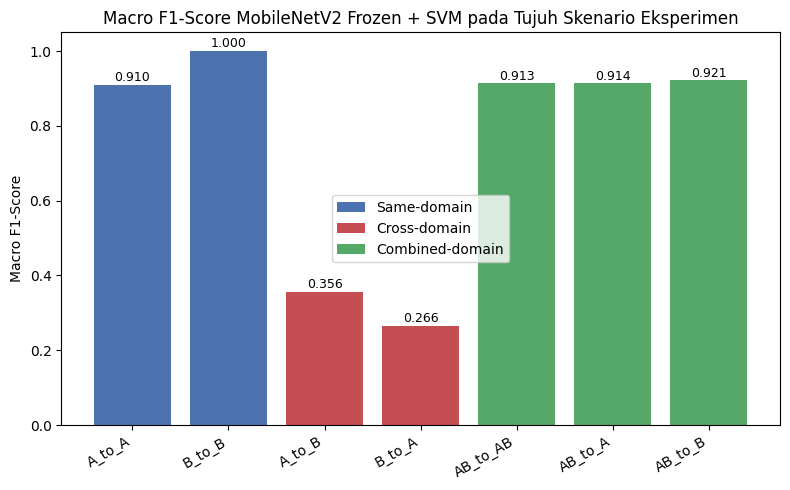

In [ ]:
# ============================================================
# GRAFIK MACRO F1 PER SKENARIO EKSPERIMEN
# MobileNetV2 Frozen + SVM
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.patches import Patch


# Urutan skenario eksperimen
order = [
    "A_to_A",
    "B_to_B",
    "A_to_B",
    "B_to_A",
    "AB_to_AB",
    "AB_to_A",
    "AB_to_B"
]


# Kelompok skenario
group_label = {

    "A_to_A": "Same-domain",

    "B_to_B": "Same-domain",

    "A_to_B": "Cross-domain",

    "B_to_A": "Cross-domain",

    "AB_to_AB": "Combined-domain",

    "AB_to_A": "Combined-domain",

    "AB_to_B": "Combined-domain"

}


# Warna kelompok
colors = {

    "Same-domain": "#4C72B0",

    "Cross-domain": "#C44E52",

    "Combined-domain": "#55A868"

}


# Ambil data sesuai urutan skenario
plot_df = (
    evaluation_results
    .set_index("evaluation")
    .loc[order]
    .reset_index()
)


plt.figure(figsize=(8,5))


bars = plt.bar(
    plot_df["evaluation"],
    plot_df["macro_f1"],
    color=[
        colors[group_label[e]]
        for e in plot_df["evaluation"]
    ]
)


# Label nilai
for bar, val in zip(
    bars,
    plot_df["macro_f1"]
):

    plt.text(
        bar.get_x() + bar.get_width()/2,
        val + 0.01,
        f"{val:.3f}",
        ha="center",
        fontsize=9
    )


plt.ylabel(
    "Macro F1-Score"
)


plt.title(
    "Macro F1-Score MobileNetV2 Frozen + SVM pada Tujuh Skenario Eksperimen"
)


plt.ylim(
    0,
    1.05
)


plt.xticks(
    rotation=30,
    ha="right"
)


# Legend
legend_items = [
    Patch(
        facecolor=color,
        label=label
    )
    for label, color in colors.items()
]


plt.legend(
    handles=legend_items
)


plt.tight_layout()


# Simpan ke folder hasil eksperimen
plt.savefig(
    RUN_DIR / "macro_f1_per_scenario.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

In [ ]:
# CEK HASIL PREDIKSI

print(
    all_predictions[
        [
            "model",
            "regime",
            "evaluation"
        ]
    ]
    .drop_duplicates()
    .sort_values(
        [
            "regime",
            "evaluation"
        ]
    )
)

                   model regime evaluation
0     mobilenetv2_frozen      a     A_to_A
353   mobilenetv2_frozen      a     A_to_B
4222  mobilenetv2_frozen     ab    AB_to_A
3869  mobilenetv2_frozen     ab   AB_to_AB
4551  mobilenetv2_frozen     ab    AB_to_B
593   mobilenetv2_frozen      b     B_to_A
329   mobilenetv2_frozen      b     B_to_B


In [ ]:
# ============================================================
# CELL 17 — PER-CLASS METRICS
# ============================================================

class_rows = []


for (
    model,
    regime,
    evaluation
), df in all_predictions.groupby(
    [
        "model",
        "regime",
        "evaluation"
    ]
):

    y_true = df["label_id"].to_numpy()

    y_pred = df["prediction_id"].to_numpy()


    p, r, f, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=range(N_CLASSES),
            zero_division=0
        )
    )


    for i, label in enumerate(TARGET_CLASSES):

        class_rows.append({

            "model": model,

            "regime": regime,

            "evaluation": evaluation,

            "class": label,

            "precision": p[i],

            "recall": r[i],

            "f1": f[i],

            "support": support[i]

        })


# ============================================================
# DATAFRAME HASIL
# ============================================================

per_class_metrics = pd.DataFrame(
    class_rows
)


# Urutan skenario untuk jurnal
evaluation_order = [
    "A_to_A",
    "B_to_B",
    "A_to_B",
    "B_to_A",
    "AB_to_AB",
    "AB_to_A",
    "AB_to_B"
]


per_class_metrics["evaluation"] = pd.Categorical(
    per_class_metrics["evaluation"],
    categories=evaluation_order,
    ordered=True
)


per_class_metrics = (
    per_class_metrics
    .sort_values(
        [
            "model",
            "evaluation",
            "class"
        ]
    )
    .reset_index(drop=True)
)


# ============================================================
# SIMPAN HASIL
# ============================================================

PER_CLASS_PATH = (
    METRICS_DIR /
    "per_class_metrics.csv"
)


per_class_metrics.to_csv(
    PER_CLASS_PATH,
    index=False
)


# ============================================================
# TAMPILKAN SEMUA HASIL
# ============================================================

display(
    per_class_metrics
)


print(
    "\nPer-class metrics tersimpan:"
)

print(
    PER_CLASS_PATH
)

,model,regime,evaluation,class,precision,recall,f1,support
0,mobilenetv2_frozen,a,A_to_A,bacterial_leaf_blight,0.862745,0.880000,0.871287,50
1,mobilenetv2_frozen,a,A_to_A,blast,0.964072,0.930636,0.947059,173
2,mobilenetv2_frozen,a,A_to_A,tungro,0.891892,0.933962,0.912442,106
3,mobilenetv2_frozen,b,B_to_B,bacterial_leaf_blight,1.000000,1.000000,1.000000,9
4,mobilenetv2_frozen,b,B_to_B,blast,1.000000,1.000000,1.000000,7
5,mobilenetv2_frozen,b,B_to_B,tungro,1.000000,1.000000,1.000000,8
6,mobilenetv2_frozen,a,A_to_B,bacterial_leaf_blight,0.322917,0.387500,0.352273,80
7,mobilenetv2_frozen,a,A_to_B,blast,0.559524,0.587500,0.573171,80
8,mobilenetv2_frozen,a,A_to_B,tungro,0.166667,0.125000,0.142857,80
9,mobilenetv2_frozen,b,B_to_A,bacterial_leaf_blight,0.125865,0.424628,0.194175,471



Per-class metrics tersimpan:
/content/drive/MyDrive/eksperimen_baru/baseline_v2/multi_regime/svm_mobilenetv2_frozen/metrics/per_class_metrics.csv


In [ ]:
# ============================================================
# CELL 18 — BOOTSTRAP MACRO F1 + WILSON ACCURACY CI
# ============================================================

from statsmodels.stats.proportion import proportion_confint

BOOTSTRAP_N = 1000

ci_rows = []


for keys, df in all_predictions.groupby(
    ["model", "regime", "evaluation"]
):

    y_true = df["label_id"].to_numpy()
    y_pred = df["prediction_id"].to_numpy()

    indices = np.arange(len(y_true))
    scores = []

    for i in range(BOOTSTRAP_N):

        sample = resample(
            indices,
            replace=True,
            n_samples=len(indices),
            stratify=y_true,
            random_state=RANDOM_STATE + i
        )

        scores.append(
            f1_score(
                y_true[sample],
                y_pred[sample],
                average="macro",
                zero_division=0
            )
        )


    f1_low, f1_high = np.percentile(
        scores,
        [2.5, 97.5]
    )

    correct = int(
        np.sum(y_true == y_pred)
    )

    acc_low, acc_high = proportion_confint(
        correct,
        len(y_true),
        alpha=0.05,
        method="wilson"
    )


    ci_rows.append({
        "model": keys[0],
        "regime": keys[1],
        "evaluation": keys[2],

        "macro_f1_ci_lower": f1_low,
        "macro_f1_ci_upper": f1_high,

        "macro_f1_ci_degenerate":
            bool(np.isclose(f1_low, f1_high)),

        "accuracy_ci_lower": acc_low,
        "accuracy_ci_upper": acc_high
    })


bootstrap_ci = pd.DataFrame(
    ci_rows
)


bootstrap_ci.to_csv(
    METRICS_DIR
    / "bootstrap_macro_f1_ci.csv",
    index=False
)


display(bootstrap_ci)

,model,regime,evaluation,macro_f1_ci_lower,macro_f1_ci_upper,macro_f1_ci_degenerate,accuracy_ci_lower,accuracy_ci_upper
0,mobilenetv2_frozen,a,A_to_A,0.874479,0.943162,False,0.890234,0.948003
1,mobilenetv2_frozen,a,A_to_B,0.304442,0.409040,False,0.308246,0.429288
2,mobilenetv2_frozen,ab,AB_to_A,0.881356,0.945067,False,0.886727,0.945501
3,mobilenetv2_frozen,ab,AB_to_AB,0.882171,0.943593,False,0.887749,0.944553
4,mobilenetv2_frozen,ab,AB_to_B,0.803922,1.000000,False,0.741512,0.976841
5,mobilenetv2_frozen,b,B_to_A,0.251674,0.279989,False,0.255217,0.285614
6,mobilenetv2_frozen,b,B_to_B,1.000000,1.000000,True,0.862024,1.000000


In [ ]:
# ============================================================
# CELL 19 — PAPER RESULT TABLES
# ============================================================


# Gabungkan hasil evaluasi dengan confidence interval

results_with_ci = (
    evaluation_results
    .merge(
        bootstrap_ci,
        on=[
            "model",
            "regime",
            "evaluation"
        ],
        how="left"
    )
)


# ============================================================
# SAME-DOMAIN
# S1 : A -> A
# S2 : B -> B
# ============================================================

same_domain = (
    results_with_ci[
        results_with_ci["evaluation"].isin(
            [
                "A_to_A",
                "B_to_B"
            ]
        )
    ]
)


# ============================================================
# CROSS-DOMAIN
# S3 : A -> B
# S4 : B -> A
# ============================================================

cross_domain = (
    results_with_ci[
        results_with_ci["evaluation"].isin(
            [
                "A_to_B",
                "B_to_A"
            ]
        )
    ]
)


# ============================================================
# COMBINED-DOMAIN
# S5 : A+B -> A+B
# S6 : A+B -> A
# S7 : A+B -> B
# ============================================================

combined_domain = (
    results_with_ci[
        results_with_ci["evaluation"].isin(
            [
                "AB_to_AB",
                "AB_to_A",
                "AB_to_B"
            ]
        )
    ]
)


# ============================================================
# SIMPAN HASIL UNTUK JURNAL
# ============================================================

same_domain.to_csv(
    METRICS_DIR /
    "table_same_domain.csv",
    index=False
)


cross_domain.to_csv(
    METRICS_DIR /
    "table_cross_domain.csv",
    index=False
)


combined_domain.to_csv(
    METRICS_DIR /
    "table_combined_domain.csv",
    index=False
)


# ============================================================
# DISPLAY HASIL
# ============================================================

print("========== SAME-DOMAIN ==========")
display(
    same_domain
)


print("\n========== CROSS-DOMAIN ==========")
display(
    cross_domain
)


print("\n========== COMBINED-DOMAIN ==========")
display(
    combined_domain
)

========== SAME-DOMAIN ==========


,experiment,model,regime,evaluation,test_split,rows,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,svm_ms_per_image,macro_f1_ci_lower,macro_f1_ci_upper,macro_f1_ci_degenerate,accuracy_ci_lower,accuracy_ci_upper
0,S1,mobilenetv2_frozen,a,A_to_A,test_a,329,0.924012,0.914866,0.906236,0.914866,0.910263,0.92439,0.027625,0.874479,0.943162,False,0.890234,0.948003
1,S2,mobilenetv2_frozen,b,B_to_B,test_b,24,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,0.079547,1.000000,1.000000,True,0.862024,1.000000



========== CROSS-DOMAIN ==========


,experiment,model,regime,evaluation,test_split,rows,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,svm_ms_per_image,macro_f1_ci_lower,macro_f1_ci_upper,macro_f1_ci_degenerate,accuracy_ci_lower,accuracy_ci_upper
2,S3,mobilenetv2_frozen,a,A_to_B,external_b_full,240,0.366667,0.366667,0.349702,0.366667,0.356100,0.356100,0.041056,0.304442,0.409040,False,0.308246,0.429288
3,S4,mobilenetv2_frozen,b,B_to_A,external_a_full,3276,0.270147,0.323840,0.369348,0.323840,0.265708,0.273839,0.035855,0.251674,0.279989,False,0.255217,0.285614



========== COMBINED-DOMAIN ==========


,experiment,model,regime,evaluation,test_split,rows,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,svm_ms_per_image,macro_f1_ci_lower,macro_f1_ci_upper,macro_f1_ci_degenerate,accuracy_ci_lower,accuracy_ci_upper
4,S5,mobilenetv2_frozen,ab,AB_to_AB,test_ab,353,0.920680,0.910842,0.915907,0.910842,0.913263,0.920658,0.041206,0.882171,0.943593,False,0.887749,0.944553
5,S6,mobilenetv2_frozen,ab,AB_to_A,test_a,329,0.920973,0.910504,0.917077,0.910504,0.913639,0.920947,0.025427,0.881356,0.945067,False,0.886727,0.945501
6,S7,mobilenetv2_frozen,ab,AB_to_B,test_b,24,0.916667,0.921296,0.921296,0.921296,0.921296,0.916667,0.111913,0.803922,1.000000,False,0.741512,0.976841


In [ ]:
# ============================================================
# CELL 20 — LITERATURE CONTEXT
# ============================================================

literature = pd.DataFrame([

    {
        "study":
            "Fawaiq et al. (2023)",

        "setting":
            "Same-dataset rice disease classification",

        "method":
            "Transfer Learning - Xception",

        "reported_result":
            "97.22% test accuracy",

        "comparison_role":
            "Same-domain context",

        "directly_comparable":
            False
    },

    {
        "study":
            "Seepanomwan (2024)",

        "setting":
            "Bidirectional cross-dataset",

        "method":
            "Pretrained CNN + augmentation",

        "reported_result":
            "~30% Field→Lab; ~20% Lab→Field",

        "comparison_role":
            "Cross-dataset context",

        "directly_comparable":
            False
    },

    {
        "study":
            "Krishna et al. (2025)",

        "setting":
            "Multi-dataset plant disease",

        "method":
            "CNN fine-tuning",

        "reported_result":
            "73.31% single; "
            "76.77% cross; "
            "80.19% combined",

        "comparison_role":
            "Dataset-combination context",

        "directly_comparable":
            False
    },

    {
        "study":
            "Aggarwal et al. (2023)",

        "setting":
            "Rice disease classification",

        "method":
            "Pretrained features + ML",

        "reported_result":
            "Up to 94% accuracy",

        "comparison_role":
            "Deep-feature + ML context",

        "directly_comparable":
            False
    }
])


LITERATURE_PATH = (
    METRICS_DIR
    / "literature_comparison_context.csv"
)


literature.to_csv(
    LITERATURE_PATH,
    index=False
)


display(literature)

,study,setting,method,reported_result,comparison_role,directly_comparable
0,Fawaiq et al. (2023),Same-dataset rice disease classification,Transfer Learning - Xception,97.22% test accuracy,Same-domain context,False
1,Seepanomwan (2024),Bidirectional cross-dataset,Pretrained CNN + augmentation,~30% Field→Lab; ~20% Lab→Field,Cross-dataset context,False
2,Krishna et al. (2025),Multi-dataset plant disease,CNN fine-tuning,73.31% single; 76.77% cross; 80.19% combined,Dataset-combination context,False
3,Aggarwal et al. (2023),Rice disease classification,Pretrained features + ML,Up to 94% accuracy,Deep-feature + ML context,False


In [ ]:
# ============================================================
# CELL 21 — METADATA DAN SIGNATURE
# ============================================================

def file_sha256(path):

    sha = hashlib.sha256()

    with open(path, "rb") as file:

        for chunk in iter(
            lambda:
                file.read(
                    1024 * 1024
                ),
            b""
        ):
            sha.update(chunk)

    return sha.hexdigest()


important_files = [
    CV_SUMMARY_PATH,
    BEST_C_PATH,
    METRICS_DIR
    / "evaluation_results.csv",
    METRICS_DIR
    / "per_class_metrics.csv",
    METRICS_DIR
    / "bootstrap_macro_f1_ci.csv"
]


artifact_signatures = {
    path.name:
        file_sha256(path)
    for path in important_files
}


metadata = {

    "notebook":
        "05_svm_multi_regime_evaluation",

    "primary_metric":
        "macro_f1",

    "feature_dimension":
        1280,

    "models":
        MODELS,

    "regimes":
        list(REGIMES),

    "cv_strategy":
        "Repeated StratifiedGroupKFold",

    "cv_folds":
        CV_FOLDS,

    "cv_seeds":
        CV_SEEDS,

    "test_used_for_selection":
        False,

    "artifact_signatures":
        artifact_signatures,

    "created_at":
        datetime.now().isoformat()
}


METADATA_PATH = (
    LOG_DIR / "metadata.json"
)


with open(
    METADATA_PATH,
    "w"
) as file:

    json.dump(
        metadata,
        file,
        indent=4
    )


print(
    "Metadata + signatures selesai."
)

Metadata + signatures selesai.


In [ ]:
import os

print("=== VARIABLES ===")

for name in [
    "best_c",
    "final_models",
    "evaluation_results",
    "per_class_results",
    "confidence_results",
    "cv_summary",
]:
    print(
        name,
        "ADA" if name in globals() else "TIDAK ADA"
    )


print("\n=== METRICS FILES ===")

for root, dirs, files in os.walk(
    METRICS_DIR
):
    for f in files:
        print(f)


print("\n=== MODEL FILES ===")

for root, dirs, files in os.walk(
    MODEL_DIR
):
    for f in files:
        print(f)

=== VARIABLES ===
best_c ADA
final_models ADA
evaluation_results ADA
per_class_results TIDAK ADA
confidence_results TIDAK ADA
cv_summary ADA

=== METRICS FILES ===
c_selection_summary.csv
best_c.csv
evaluation_results.csv
per_class_metrics.csv
bootstrap_macro_f1_ci.csv
table_same_domain.csv
table_combined_domain.csv
table_cross_domain.csv
literature_comparison_context.csv

=== MODEL FILES ===
mobilenetv2_frozen_a.joblib
mobilenetv2_frozen_ab.joblib
mobilenetv2_frozen_b.joblib


In [ ]:
# ============================================================
# CELL 22 — FINAL VALIDATION (FIXED)
# ============================================================

required_files = {

    "best_c":
        METRICS_DIR
        / "best_c.csv",

    "final_models":
        MODEL_DIR,

    "cv_rows":
        CV_DIR,

    "evaluations":
        METRICS_DIR
        / "evaluation_results.csv",

    "per_class":
        METRICS_DIR
        / "per_class_metrics.csv",

    "confidence_intervals":
        METRICS_DIR
        / "bootstrap_macro_f1_ci.csv"
}


failed = []


for name, path in required_files.items():

    if not path.exists():

        failed.append(
            name
        )


if failed:

    raise RuntimeError(
        f"Final validation gagal: {failed}"
    )


print(
    "Final validation: LULUS"
)


print(
    "\nOutput tersedia:"
)

for name, path in required_files.items():

    print(
        f"{name:<20}: {path}"
    )

Final validation: LULUS

Output tersedia:
best_c              : /content/drive/MyDrive/eksperimen_baru/baseline_v2/multi_regime/svm_mobilenetv2_frozen/metrics/best_c.csv
final_models        : /content/drive/MyDrive/eksperimen_baru/baseline_v2/multi_regime/svm_mobilenetv2_frozen/models
cv_rows             : /content/drive/MyDrive/eksperimen_baru/baseline_v2/multi_regime/svm_mobilenetv2_frozen/cv
evaluations         : /content/drive/MyDrive/eksperimen_baru/baseline_v2/multi_regime/svm_mobilenetv2_frozen/metrics/evaluation_results.csv
per_class           : /content/drive/MyDrive/eksperimen_baru/baseline_v2/multi_regime/svm_mobilenetv2_frozen/metrics/per_class_metrics.csv
confidence_intervals: /content/drive/MyDrive/eksperimen_baru/baseline_v2/multi_regime/svm_mobilenetv2_frozen/metrics/bootstrap_macro_f1_ci.csv


CONFUSION MATRIX : A_to_A


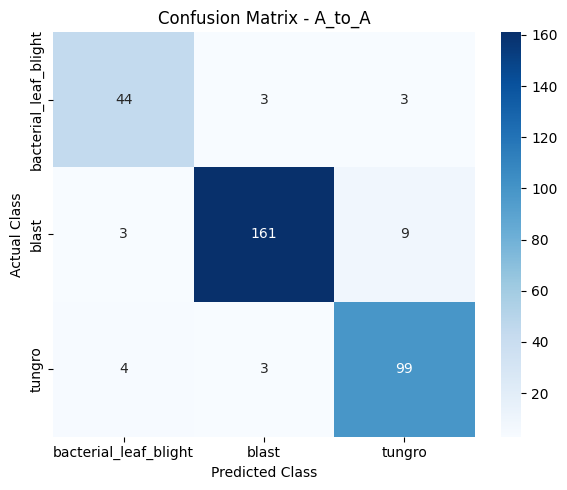

Disimpan: /content/drive/MyDrive/eksperimen_baru/baseline_v2/multi_regime/svm_mobilenetv2_frozen/confusion_matrix/confusion_matrix_A_to_A.png
CONFUSION MATRIX : B_to_B


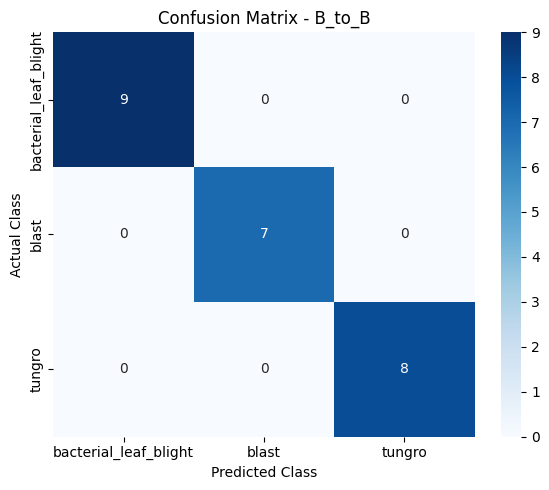

Disimpan: /content/drive/MyDrive/eksperimen_baru/baseline_v2/multi_regime/svm_mobilenetv2_frozen/confusion_matrix/confusion_matrix_B_to_B.png
CONFUSION MATRIX : A_to_B


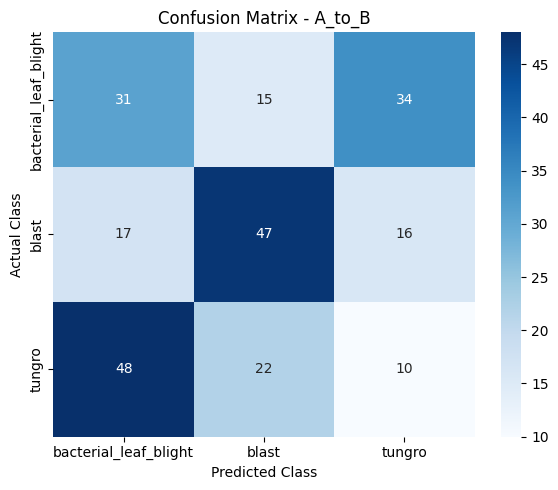

Disimpan: /content/drive/MyDrive/eksperimen_baru/baseline_v2/multi_regime/svm_mobilenetv2_frozen/confusion_matrix/confusion_matrix_A_to_B.png
CONFUSION MATRIX : B_to_A


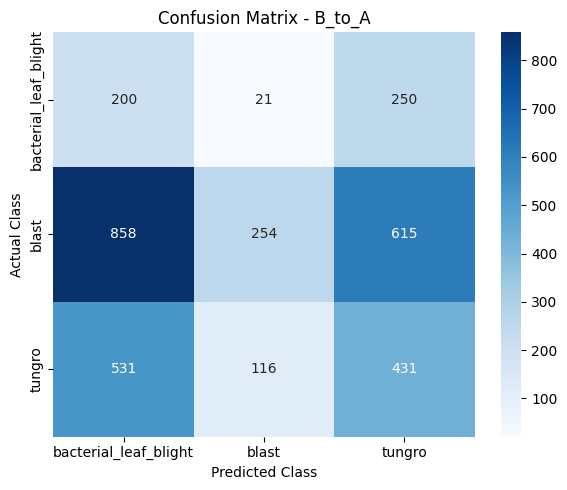

Disimpan: /content/drive/MyDrive/eksperimen_baru/baseline_v2/multi_regime/svm_mobilenetv2_frozen/confusion_matrix/confusion_matrix_B_to_A.png
CONFUSION MATRIX : AB_to_AB


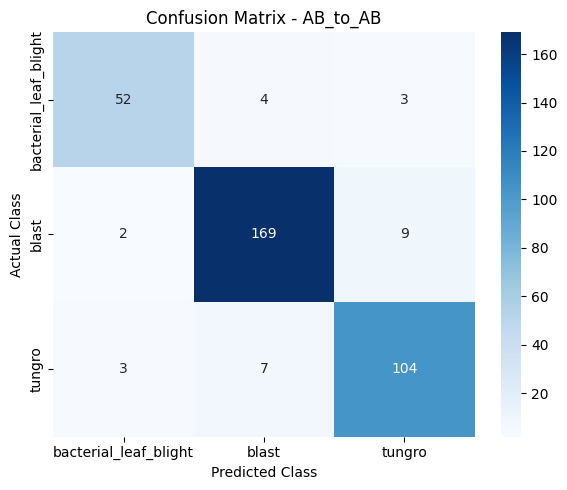

Disimpan: /content/drive/MyDrive/eksperimen_baru/baseline_v2/multi_regime/svm_mobilenetv2_frozen/confusion_matrix/confusion_matrix_AB_to_AB.png
CONFUSION MATRIX : AB_to_A


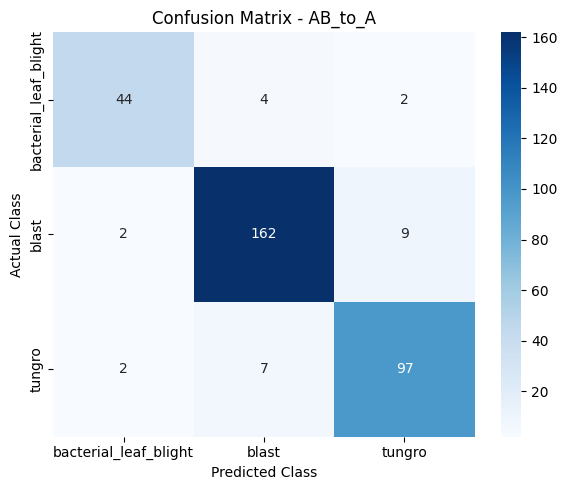

Disimpan: /content/drive/MyDrive/eksperimen_baru/baseline_v2/multi_regime/svm_mobilenetv2_frozen/confusion_matrix/confusion_matrix_AB_to_A.png
CONFUSION MATRIX : AB_to_B


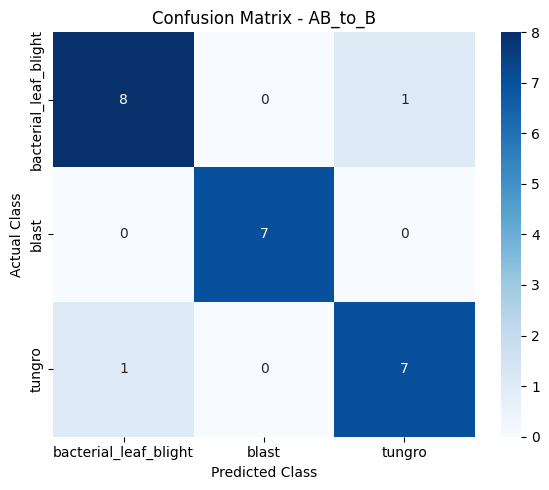

Disimpan: /content/drive/MyDrive/eksperimen_baru/baseline_v2/multi_regime/svm_mobilenetv2_frozen/confusion_matrix/confusion_matrix_AB_to_B.png


In [ ]:
# ============================================================
# CONFUSION MATRIX FINAL
# MobileNetV2 Frozen + SVM
# ============================================================

CONFUSION_SCENARIOS = [
    "A_to_A",
    "B_to_B",
    "A_to_B",
    "B_to_A",
    "AB_to_AB",
    "AB_to_A",
    "AB_to_B"
]


for evaluation_name in CONFUSION_SCENARIOS:

    print("=" * 60)
    print(f"CONFUSION MATRIX : {evaluation_name}")
    print("=" * 60)


    cm_data = all_predictions[
        all_predictions["evaluation"]
        ==
        evaluation_name
    ]


    if len(cm_data) == 0:

        print(
            "Data tidak ditemukan\n"
        )

        continue


    y_true = cm_data[
        "label_id"
    ].to_numpy()


    y_pred = cm_data[
        "prediction_id"
    ].to_numpy()


    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=range(N_CLASSES)
    )


    plt.figure(
        figsize=(6,5)
    )


    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=TARGET_CLASSES,
        yticklabels=TARGET_CLASSES
    )


    plt.xlabel(
        "Predicted Class"
    )


    plt.ylabel(
        "Actual Class"
    )


    plt.title(
        f"Confusion Matrix - {evaluation_name}"
    )


    plt.tight_layout()


    # simpan hasil
    save_path = (
        CONFUSION_DIR /
        f"confusion_matrix_{evaluation_name}.png"
    )


    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()


    print(
        "Disimpan:",
        save_path
    )

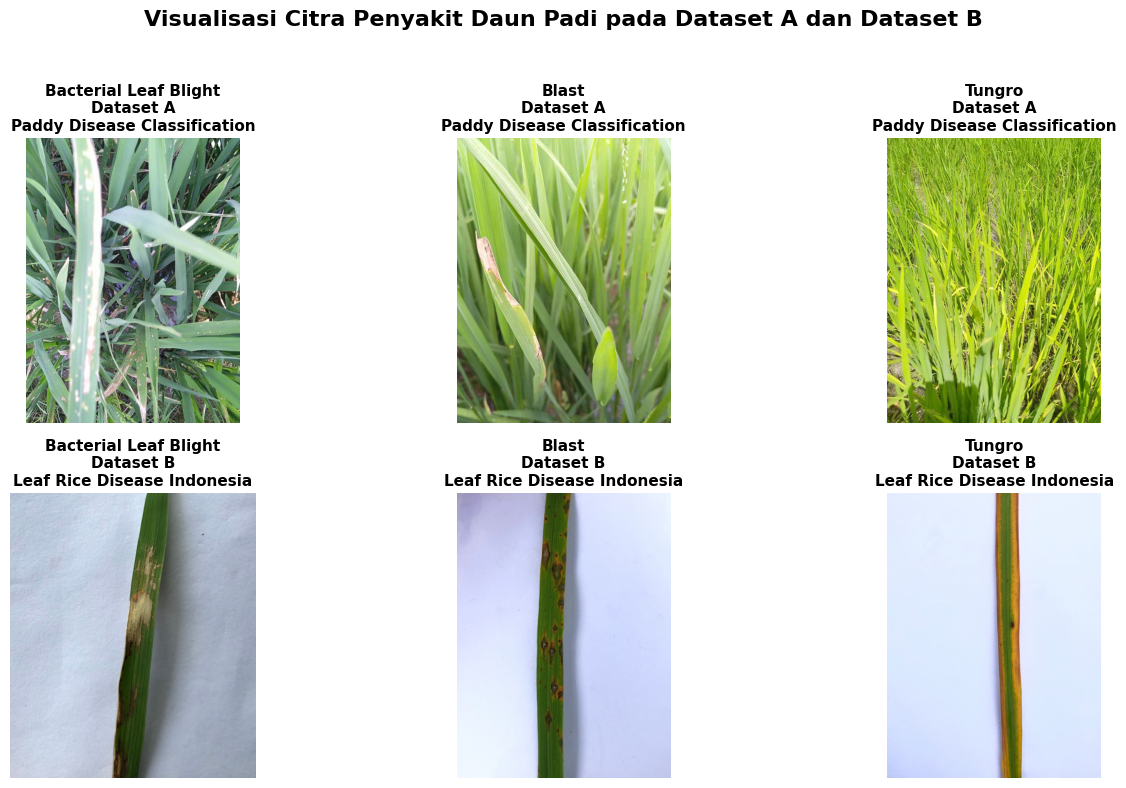

Disimpan di: /content/drive/MyDrive/eksperimen_baru/baseline_v2/multi_regime/svm_mobilenetv2_frozen/visual_dataset_A_vs_B_landscape.png


In [ ]:
# ============================================================
# VISUALISASI DATASET A vs DATASET B
# LAYOUT MENYAMPING: 2 BARIS x 3 KOLOM
# ============================================================

import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd


# Load index dataset
index_a = pd.read_csv(FROZEN_ROOT / "test_a_index.csv")
index_b = pd.read_csv(FROZEN_ROOT / "test_b_index.csv")


classes = [
    "bacterial_leaf_blight",
    "blast",
    "tungro"
]

class_name = {
    "bacterial_leaf_blight": "Bacterial Leaf Blight",
    "blast": "Blast",
    "tungro": "Tungro"
}


def crop_center(img, ratio=0.85):
    w, h = img.size
    nw = int(w * ratio)
    nh = int(h * ratio)

    left = (w - nw) // 2
    top = (h - nh) // 2

    return img.crop((left, top, left + nw, top + nh))


# ============================================================
# AMBIL 1 SAMPEL PER KELAS
# ============================================================

samples_a = []
samples_b = []

for cls in classes:
    row_a = (
        index_a[index_a["label"] == cls]
        .sample(n=1, random_state=42)
        .iloc[0]
    )

    row_b = (
        index_b[index_b["label"] == cls]
        .sample(n=1, random_state=42)
        .iloc[0]
    )

    samples_a.append((cls, row_a))
    samples_b.append((cls, row_b))


# ============================================================
# PLOT
# ============================================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(14, 8)
)

fig.suptitle(
    "Visualisasi Citra Penyakit Daun Padi pada Dataset A dan Dataset B",
    fontsize=16,
    fontweight="bold",
    y=0.98
)


# --------------------------
# Baris 1 = Dataset A
# --------------------------
for col, (cls, row) in enumerate(samples_a):
    img = Image.open(row["path"]).convert("RGB")
    img = crop_center(img, ratio=0.85)

    axes[0, col].imshow(img)
    axes[0, col].axis("off")
    axes[0, col].set_title(
        f"{class_name[cls]}\nDataset A\nPaddy Disease Classification",
        fontsize=11,
        fontweight="bold"
    )


# --------------------------
# Baris 2 = Dataset B
# --------------------------
for col, (cls, row) in enumerate(samples_b):
    img = Image.open(row["path"]).convert("RGB")
    img = crop_center(img, ratio=0.85)

    axes[1, col].imshow(img)
    axes[1, col].axis("off")
    axes[1, col].set_title(
        f"{class_name[cls]}\nDataset B\nLeaf Rice Disease Indonesia",
        fontsize=11,
        fontweight="bold"
    )


plt.tight_layout(rect=[0, 0, 1, 0.95])

save_path = RUN_DIR / "visual_dataset_A_vs_B_landscape.png"

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Disimpan di:", save_path)

In [ ]:
# ============================================================
# EXPORT SEMUA CONFUSION MATRIX FINAL
# ============================================================

import os
import shutil
from pathlib import Path
from google.colab import files


# Folder confusion matrix hasil eksperimen
CM_SOURCE = CONFUSION_DIR


# Folder sementara export
CM_EXPORT = Path(
    "/content/cm_export_final"
)


# hapus folder lama
if CM_EXPORT.exists():
    shutil.rmtree(CM_EXPORT)


CM_EXPORT.mkdir(
    exist_ok=True
)


# copy semua confusion matrix
cm_files = list(
    CM_SOURCE.glob(
        "confusion_matrix_*.png"
    )
)


print("Jumlah confusion matrix ditemukan:", len(cm_files))


for f in cm_files:

    shutil.copy(
        f,
        CM_EXPORT / f.name
    )

    print(
        "Copy:",
        f.name
    )


# buat zip
zip_path = shutil.make_archive(
    "/content/cm_export_final",
    "zip",
    CM_EXPORT
)


print("\nZIP dibuat:")
print(zip_path)


# download
files.download(
    zip_path
)

Jumlah confusion matrix ditemukan: 7
Copy: confusion_matrix_A_to_A.png
Copy: confusion_matrix_B_to_B.png
Copy: confusion_matrix_A_to_B.png
Copy: confusion_matrix_B_to_A.png
Copy: confusion_matrix_AB_to_AB.png
Copy: confusion_matrix_AB_to_A.png
Copy: confusion_matrix_AB_to_B.png

ZIP dibuat:
/content/cm_export_final.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("Notebook 05_SVM_MOBILNETV2_FROZEN selesai.")

Notebook 05_SVM_MOBILNETV2_FROZEN selesai.


In [ ]:
# ============================================================
# FINAL EXPORT — SEMUA HASIL UNTUK JURNAL
# MobileNetV2 Frozen + SVM
# ============================================================

import shutil
from pathlib import Path


# Folder final jurnal
FINAL_JOURNAL_DIR = (
    RUN_DIR.parent /
    "JURNAL_FINAL_MobileNetV2_Frozen_SVM"
)


# hapus jika sudah ada versi lama
if FINAL_JOURNAL_DIR.exists():
    shutil.rmtree(FINAL_JOURNAL_DIR)


FINAL_JOURNAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# COPY FOLDER HASIL
# ============================================================

folders = {

    "metrics": METRICS_DIR,

    "confusion_matrix": CONFUSION_DIR,

    "models": MODEL_DIR,

    "predictions": PREDICTION_DIR,

    "cv": CV_DIR,

    "logs": LOG_DIR

}


for name, source in folders.items():

    if source.exists():

        shutil.copytree(
            source,
            FINAL_JOURNAL_DIR / name,
            dirs_exist_ok=True
        )

        print(
            "✓ Copy:",
            name
        )

    else:

        print(
            "Tidak ditemukan:",
            source
        )



# ============================================================
# COPY FILE VISUALISASI
# ============================================================

files = [

    RUN_DIR / "macro_f1_per_scenario.png",

    RUN_DIR / "visual_dataset_A_vs_B_landscape.png",

    METRICS_DIR / "evaluation_results.csv",

    METRICS_DIR / "per_class_metrics.csv",

    METRICS_DIR / "table_same_domain.csv",

    METRICS_DIR / "table_cross_domain.csv",

    METRICS_DIR / "table_combined_domain.csv",

]


for file in files:

    if file.exists():

        shutil.copy(
            file,
            FINAL_JOURNAL_DIR / file.name
        )

        print(
            "✓ Copy file:",
            file.name
        )



# ============================================================
# BUAT ZIP
# ============================================================

zip_file = shutil.make_archive(
    str(FINAL_JOURNAL_DIR),
    "zip",
    FINAL_JOURNAL_DIR
)


print("\n================================")
print("EXPORT SELESAI")
print("Folder:")
print(FINAL_JOURNAL_DIR)

print("\nZIP:")
print(zip_file)

print("================================")

✓ Copy: metrics
✓ Copy: confusion_matrix
✓ Copy: models
✓ Copy: predictions
✓ Copy: cv
✓ Copy: logs
✓ Copy file: macro_f1_per_scenario.png
✓ Copy file: visual_dataset_A_vs_B_landscape.png
✓ Copy file: evaluation_results.csv
✓ Copy file: per_class_metrics.csv
✓ Copy file: table_same_domain.csv
✓ Copy file: table_cross_domain.csv
✓ Copy file: table_combined_domain.csv

EXPORT SELESAI
Folder:
/content/drive/MyDrive/eksperimen_baru/baseline_v2/multi_regime/JURNAL_FINAL_MobileNetV2_Frozen_SVM

ZIP:
/content/drive/MyDrive/eksperimen_baru/baseline_v2/multi_regime/JURNAL_FINAL_MobileNetV2_Frozen_SVM.zip


In [ ]:
from google.colab import files

zip_path = (
    "/content/drive/MyDrive/eksperimen_baru/"
    "baseline_v2/multi_regime/"
    "JURNAL_FINAL_MobileNetV2_Frozen_SVM.zip"
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ==========================================================
# FINAL STATUS
# ==========================================================

print("=" * 60)
print("05_SVM_Frozen_mobilnetv2 — SELESAI")
print("=" * 60)

print("Model final      : LULUS")
print("Evaluation       : LULUS")
print("Confidence CI    : LULUS")
print("Confusion Matrix : LULUS")
print("Per-class report : LULUS")
print("=" * 60)

05_SVM_Frozen_mobilnetv2 — SELESAI
Model final      : LULUS
Evaluation       : LULUS
Confidence CI    : LULUS
Confusion Matrix : LULUS
Per-class report : LULUS
